# MVP Predictive Lead Scoring & Next Best Offer (Door-to-Door Sales)
**Studi Kasus:** PT EcoCare Indo Pasifik Tbk (Hygiene, Pest Control, Termite Control, & Fumigasi)

Notebook ini berisi *end-to-end pipeline* untuk:
1. Memuat dan mengeksplorasi dataset observasi lapangan (`ecocare_sales_prospecting_mvp_1000.csv`).
2. Melakukan *preprocessing* & *encoding* atribut kategorikal dan numerik.
3. Melatih 2 model utama sekaligus:
   - **Model 1 (Lead Scoring):** Memprediksi probabilitas calon pelanggan membeli (`status_konversi`).
   - **Model 2 (Product Recommendation / Next Best Offer):** Merekomendasikan lini layanan utama & *cross-selling* (`rekomendasi_lini_utama`) beserta persentase kecocokannya.
4. Simulasi fungsi inferensi untuk aplikasi *sales canvassing* di lapangan.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, accuracy_score

import warnings
warnings.filterwarnings('ignore')

# Load dataset
df = pd.read_csv('ecocare_sales_prospecting_mvp_1000.csv')
print(f'Ukuran Dataset: {df.shape[0]} baris, {df.shape[1]} kolom')
df.head()

Ukuran Dataset: 1000 baris, 25 kolom


,prospect_id,segmen_industri,skala_area_m2,traffic_harian,jam_operasional,rating_online_kebersihan,kondisi_aroma_toilet,fasilitas_cuci_tangan,ketersediaan_sanitary_bin,kondisi_lantai_pintu_masuk,...,kondisi_sanitasi_drainase,usia_dan_status_bangunan,dominasi_material_kayu,indikasi_lembap_atau_rayap,penyimpanan_komoditas_arsip,tuntutan_regulasi_audit,kondisi_vendor_saat_ini,status_konversi,rekomendasi_lini_utama,potensi_cross_sell
0,EC-PROS-0001,Hotel_Hospital,9581,Sangat_Tinggi,24_Jam,3.3,Pengap,Dispenser_Manual,Ada_Tertutup,Kering_Ada_Mat,...,Saluran_Kotor_Sisa_Makanan,Baru_<5Thn,Minim_Baja_Kaca,Aman_Kering,Tidak_Ada,0,Ada_Komplain_Tidak_Puas,1,Pest_Control,Hygiene
1,EC-PROS-0002,Office_Tower,4599,Sedang,12_Jam,3.0,Pengap,Dispenser_Manual,Ada_Tertutup,Banyak_Debu_Sepatu,...,Bersih_Lancar,Baru_<5Thn,Sedang_Furnitur,Aman_Kering,Gudang_Arsip_Kertas,1,Ada_Komplain_Tidak_Puas,0,Fumigasi,Hygiene
2,EC-PROS-0003,Resto_F&B,1132,Tinggi,24_Jam,3.3,Bau_Menyengat,Lengkap_Otomatis,Tempat_Sampah_Biasa,Kering_Ada_Mat,...,Ada_Genangan_Air,Sedang_5-10Thn,Minim_Baja_Kaca,Ada_Jalur_Tanah_Kayu_Keropos,Tidak_Ada,0,Ada_Komplain_Tidak_Puas,1,Pest_Control,Hygiene
3,EC-PROS-0004,Warehouse_Pabrik,5986,Rendah,12_Jam,3.7,Segar,Dispenser_Manual,Tidak_Ada,Lembap_Licin,...,Ada_Genangan_Air,Tua_>10Thn,Sedang_Furnitur,Dinding_Rembes_Bocor,Silo_Pangan_Karung,1,Belum_Ada_Internal,0,Fumigasi,Termite_Control
4,EC-PROS-0005,Hotel_Hospital,4988,Sangat_Tinggi,24_Jam,3.3,Segar,Lengkap_Otomatis,Tempat_Sampah_Biasa,Kering_Ada_Mat,...,Bersih_Lancar,Tua_>10Thn,Sedang_Furnitur,Ada_Jalur_Tanah_Kayu_Keropos,Gudang_Arsip_Kertas,1,Belum_Ada_Internal,1,Pest_Control,Termite_Control


## 1. Exploratory Data Analysis (EDA) Singkat
Melihat distribusi konversi dan proporsi rekomendasi keempat lini layanan EcoCare.

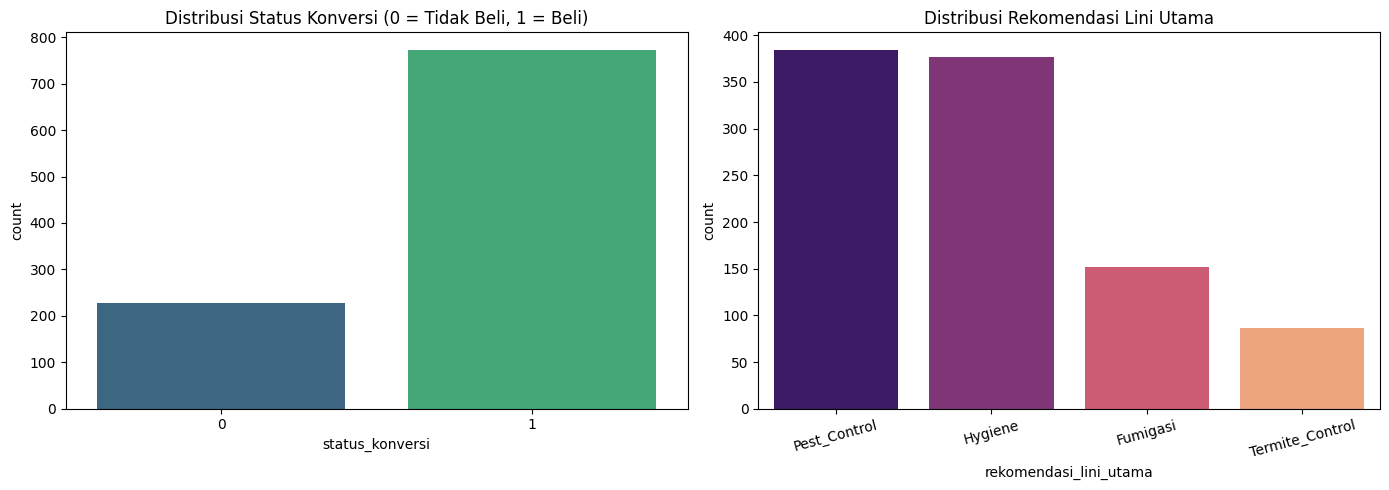

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x='status_konversi', palette='viridis', ax=axes[0])
axes[0].set_title('Distribusi Status Konversi (0 = Tidak Beli, 1 = Beli)')

sns.countplot(data=df, x='rekomendasi_lini_utama', order=df['rekomendasi_lini_utama'].value_counts().index, palette='magma', ax=axes[1])
axes[1].set_title('Distribusi Rekomendasi Lini Utama')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

## 2. Feature Engineering & Preprocessing Pipeline
Memisahkan fitur observasi lapangan (`X`) dengan target prediksi (`y_conv` untuk probabilitas beli dan `y_line` untuk rekomendasi lini produk).

In [3]:
feature_cols = [
    'segmen_industri', 'skala_area_m2', 'traffic_harian', 'jam_operasional', 'rating_online_kebersihan',
    'kondisi_aroma_toilet', 'fasilitas_cuci_tangan', 'ketersediaan_sanitary_bin', 'kondisi_lantai_pintu_masuk', 'sirkulasi_udara_ruang',
    'jarak_tempat_sampah_m', 'proteksi_akses_pintu', 'aktivitas_loading_barang', 'indikasi_visual_hama', 'kondisi_sanitasi_drainase',
    'usia_dan_status_bangunan', 'dominasi_material_kayu', 'indikasi_lembap_atau_rayap',
    'penyimpanan_komoditas_arsip', 'tuntutan_regulasi_audit', 'kondisi_vendor_saat_ini'
]

numeric_cols = ['skala_area_m2', 'rating_online_kebersihan', 'tuntutan_regulasi_audit']
categorical_cols = [c for c in feature_cols if c not in numeric_cols]

X = df[feature_cols]
y_conv = df['status_konversi']
y_line = df['rekomendasi_lini_utama']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

X_train, X_test, y_conv_train, y_conv_test, y_line_train, y_line_test = train_test_split(
    X, y_conv, y_line, test_size=0.2, random_state=42, stratify=y_line
)
print(f'Data Training: {X_train.shape[0]} sampel | Data Testing: {X_test.shape[0]} sampel')

Data Training: 800 sampel | Data Testing: 200 sampel


## 3. Training Model 1: Prediksi Probabilitas Membeli (Lead Scoring)
Menggunakan `RandomForestClassifier` untuk memprediksi peluang closing dan mengekstrak skor probabilitas (`predict_proba`).

In [4]:
model_lead_scoring = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, class_weight='balanced'))
])

model_lead_scoring.fit(X_train, y_conv_train)

y_conv_pred = model_lead_scoring.predict(X_test)
y_conv_prob = model_lead_scoring.predict_proba(X_test)[:, 1]

print('=== EVALUASI MODEL 1: LEAD SCORING (STATUS KONVERSI) ===')
print(f'ROC-AUC Score : {roc_auc_score(y_conv_test, y_conv_prob):.4f}')
print(f'Accuracy      : {accuracy_score(y_conv_test, y_conv_pred):.4f}\n')
print(classification_report(y_conv_test, y_conv_pred))

=== EVALUASI MODEL 1: LEAD SCORING (STATUS KONVERSI) ===
ROC-AUC Score : 0.8083
Accuracy      : 0.8200

              precision    recall  f1-score   support

           0       0.73      0.40      0.51        48
           1       0.83      0.95      0.89       152

    accuracy                           0.82       200
   macro avg       0.78      0.67      0.70       200
weighted avg       0.81      0.82      0.80       200



## 4. Training Model 2: Rekomendasi Lini Layanan (Next Best Offer)
Memprediksi lini layanan mana (*Hygiene*, *Pest Control*, *Termite Control*, atau *Fumigasi*) yang paling tepat ditawarkan oleh sales saat melakukan kunjungan.

In [5]:
model_product_rec = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42))
])

model_product_rec.fit(X_train, y_line_train)
y_line_pred = model_product_rec.predict(X_test)

print('=== EVALUASI MODEL 2: REKOMENDASI LINI LAYANAN ===')
print(f'Accuracy : {accuracy_score(y_line_test, y_line_pred):.4f}\n')
print(classification_report(y_line_test, y_line_pred))

=== EVALUASI MODEL 2: REKOMENDASI LINI LAYANAN ===
Accuracy : 0.8200

                 precision    recall  f1-score   support

       Fumigasi       0.82      1.00      0.90        31
        Hygiene       0.79      0.87      0.83        75
   Pest_Control       0.84      0.84      0.84        77
Termite_Control       1.00      0.18      0.30        17

       accuracy                           0.82       200
      macro avg       0.86      0.72      0.72       200
   weighted avg       0.83      0.82      0.80       200



## 5. Feature Importance (Faktor Penentu Utama di Lapangan)
Melihat atribut observasi apa saja yang paling kuat memengaruhi keputusan model.

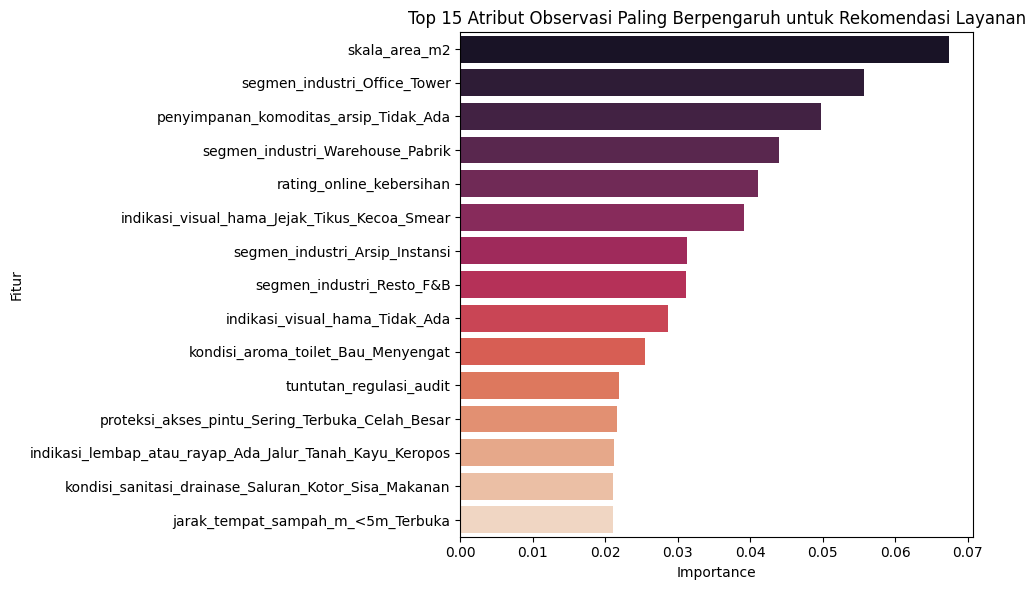

In [6]:
ohe_feature_names = model_product_rec.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(categorical_cols)
all_feature_names = numeric_cols + list(ohe_feature_names)

importances = model_product_rec.named_steps['classifier'].feature_importances_
feat_imp_df = pd.DataFrame({'Fitur': all_feature_names, 'Importance': importances}).sort_values('Importance', ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp_df, x='Importance', y='Fitur', palette='rocket')
plt.title('Top 15 Atribut Observasi Paling Berpengaruh untuk Rekomendasi Layanan')
plt.tight_layout()
plt.show()

## 6. Simulasi Asisten Sales Door-to-Door (Inference Function)
Fungsi ini mensimulasikan apa yang tampil di layar HP sales setelah mengisi *checklist* observasi singkat di lokasi calon pelanggan.

In [7]:
def prediksi_prospek_lapangan(data_input_dict):
    input_df = pd.DataFrame([data_input_dict])
    
    # 1. Hitung probabilitas konversi
    prob_beli = model_lead_scoring.predict_proba(input_df)[0, 1] * 100
    status_lead = 'HOT PROSPECT (Prioritas Tinggi)' if prob_beli >= 70 else ('WARM PROSPECT (Potensial)' if prob_beli >= 45 else 'COLD PROSPECT (Prioritas Rendah)')
    
    # 2. Hitung distribusi kecocokan lini produk
    classes = model_product_rec.named_steps['classifier'].classes_
    probs_lini = model_product_rec.predict_proba(input_df)[0] * 100
    lini_ranking = sorted(zip(classes, probs_lini), key=lambda x: x[1], reverse=True)
    
    utama_nama, utama_skor = lini_ranking[0]
    cross_nama, cross_skor = lini_ranking[1]
    
    print('============================================================')
    print('       HASIL ANALISIS AI SALES PROSPECTING ECOCARE          ')
    print('============================================================')
    print(f'Segmen Prospek        : {data_input_dict["segmen_industri"]} ({data_input_dict["skala_area_m2"]} m2)')
    print(f'Probabilitas Membeli  : {prob_beli:.1f}% -> [{status_lead}]')
    print('------------------------------------------------------------')
    print(f'REKOMENDASI UTAMA     : {utama_nama} (Kecocokan: {utama_skor:.1f}%)')
    if cross_skor >= 20:
        print(f'REKOMENDASI CROSS-SELL: {cross_nama} (Kecocokan: {cross_skor:.1f}%)')
    else:
        print('REKOMENDASI CROSS-SELL: Fokus pada penawaran utama terlebih dahulu')
    print('------------------------------------------------------------')
    print('Rincian Skor Kebutuhan Seluruh Lini:')
    for lini, skor in lini_ranking:
        print(f'  - {lini:<16}: {skor:.1f}%')
    print('============================================================\n')

# Skenario Uji 1: Sales mendatangi Restoran ramai yang bau toiletnya menyengat & banyak lalat/indikasi tikus
contoh_prospek_resto = {
    'segmen_industri': 'Resto_F&B',
    'skala_area_m2': 350,
    'traffic_harian': 'Tinggi',
    'jam_operasional': '14_Jam',
    'rating_online_kebersihan': 3.2,
    'kondisi_aroma_toilet': 'Bau_Menyengat',
    'fasilitas_cuci_tangan': 'Sabun_Batang_Curah',
    'ketersediaan_sanitary_bin': 'Tempat_Sampah_Biasa',
    'kondisi_lantai_pintu_masuk': 'Lembap_Licin',
    'sirkulasi_udara_ruang': 'Pengap_Panas',
    'jarak_tempat_sampah_m': '<5m_Terbuka',
    'proteksi_akses_pintu': 'Sering_Terbuka_Celah_Besar',
    'aktivitas_loading_barang': 'Tinggi_Tanpa_Inspeksi',
    'indikasi_visual_hama': 'Jejak_Tikus_Kecoa_Smear',
    'kondisi_sanitasi_drainase': 'Saluran_Kotor_Sisa_Makanan',
    'usia_dan_status_bangunan': 'Sedang_5-10Thn',
    'dominasi_material_kayu': 'Sedang_Furnitur',
    'indikasi_lembap_atau_rayap': 'Aman_Kering',
    'penyimpanan_komoditas_arsip': 'Tidak_Ada',
    'tuntutan_regulasi_audit': 1,
    'kondisi_vendor_saat_ini': 'Ada_Komplain_Tidak_Puas'
}

prediksi_prospek_lapangan(contoh_prospek_resto)

# Skenario Uji 2: Sales mendatangi Gedung Perkantoran dengan masalah sanitasi toilet
contoh_prospek_office = {
    'segmen_industri': 'Office_Tower',
    'skala_area_m2': 4500,
    'traffic_harian': 'Sangat_Tinggi',
    'jam_operasional': '12_Jam',
    'rating_online_kebersihan': 3.6,
    'kondisi_aroma_toilet': 'Bau_Menyengat',
    'fasilitas_cuci_tangan': 'Kosong_Tidak_Terawat',
    'ketersediaan_sanitary_bin': 'Tidak_Ada',
    'kondisi_lantai_pintu_masuk': 'Banyak_Debu_Sepatu',
    'sirkulasi_udara_ruang': 'AC_Sentral_Baik',
    'jarak_tempat_sampah_m': '>15m_Terisolasi',
    'proteksi_akses_pintu': 'Standar_Tertutup',
    'aktivitas_loading_barang': 'Rendah',
    'indikasi_visual_hama': 'Tidak_Ada',
    'kondisi_sanitasi_drainase': 'Bersih_Lancar',
    'usia_dan_status_bangunan': 'Baru_<5Thn',
    'dominasi_material_kayu': 'Minim_Baja_Kaca',
    'indikasi_lembap_atau_rayap': 'Aman_Kering',
    'penyimpanan_komoditas_arsip': 'Tidak_Ada',
    'tuntutan_regulasi_audit': 0,
    'kondisi_vendor_saat_ini': 'Belum_Ada_Internal'
}

prediksi_prospek_lapangan(contoh_prospek_office)

       HASIL ANALISIS AI SALES PROSPECTING ECOCARE          
Segmen Prospek        : Resto_F&B (350 m2)
Probabilitas Membeli  : 94.3% -> [HOT PROSPECT (Prioritas Tinggi)]
------------------------------------------------------------
REKOMENDASI UTAMA     : Pest_Control (Kecocokan: 83.8%)
REKOMENDASI CROSS-SELL: Fokus pada penawaran utama terlebih dahulu
------------------------------------------------------------
Rincian Skor Kebutuhan Seluruh Lini:
  - Pest_Control    : 83.8%
  - Hygiene         : 13.2%
  - Termite_Control : 3.0%
  - Fumigasi        : 0.0%

       HASIL ANALISIS AI SALES PROSPECTING ECOCARE          
Segmen Prospek        : Office_Tower (4500 m2)
Probabilitas Membeli  : 84.2% -> [HOT PROSPECT (Prioritas Tinggi)]
------------------------------------------------------------
REKOMENDASI UTAMA     : Hygiene (Kecocokan: 97.4%)
REKOMENDASI CROSS-SELL: Fokus pada penawaran utama terlebih dahulu
------------------------------------------------------------
Rincian Skor Kebutuha